<a href="https://colab.research.google.com/github/hafizhrifandi11/telco_customer_churn_analysis/blob/main/Telco_Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Business Understanding

## 1.1 Overview of Analysis

### Project Background
Customer churn is an important business concern for telecommunications companies because customer retention can affect recurring revenue and long-term business performance. Understanding customer characteristics, service usage, payment behavior, and customer status can help the company identify patterns associated with customer churn.

### Project Objective
This project aims to analyze the IBM Telco Customer Churn dataset to understand customer churn patterns, identify customer segments with different churn rates, and generate actionable insights to support customer retention strategies.

### Scope of Analysis
The analysis covers six datasets:

1. **Customer_Info** — Customer demographics and household characteristics.
2. **Location_Data** — Customer geographic information.
3. **Online_Services** — Subscribed telecommunications and online services.
4. **Payment_Info** — Contract types, payment methods, charges, and revenue-related information.
5. **Service_Options** — Tenure, service packages, data usage, and customer referrals.
6. **Status_Analysis** — Customer status, churn indicators, satisfaction score, customer lifetime value (CLTV), and churn reasons.

These datasets will be examined and integrated through the common `customer_id` identifier, subject to relationship and data-quality checks.

### Analytical Approach
The project will follow these stages:

1. Problem statement and business understanding.
2. Data preprocessing and data-quality assessment.
3. Exploratory Data Analysis (EDA).
4. Insight generation and interpretation.
5. Interactive dashboard development using Power BI.
6. Data-driven business recommendations.

### Expected Outcome
The expected outcome is a clear understanding of customer churn patterns, identification of customer segments associated with higher churn rates, an interactive dashboard, and practical recommendations to support customer retention decisions.

## 1.2 Problem Statement & Analytical Objectives

### Problem Statement

Customer churn is a key business concern for telecommunications companies because losing customers may affect recurring revenue and long-term customer relationships. However, the extent of churn and the customer characteristics associated with it need to be examined using the available data.

This analysis aims to investigate customer churn patterns and examine how demographic characteristics, service subscriptions, contract types, payment behavior, customer tenure, and other relevant variables are associated with churn.

The analysis will use the `churn_value` field in the `Status_Analysis` table as the primary candidate target variable, subject to verification of its definition and value distribution during data understanding.

### Analytical Objectives

The analysis has the following objectives:

1. **Measure Customer Churn**  
   Calculate the number and proportion of customers who have churned to establish a baseline for evaluating customer retention.

2. **Identify Churn-Related Factors**  
   Examine the relationship between customer churn and relevant demographic, service, contract, payment, and tenure characteristics.

3. **Compare Customer Segments**  
   Identify differences in churn rates across customer groups to determine which segments warrant further investigation.

4. **Evaluate Customer Value and Satisfaction**  
   Explore whether churn patterns differ according to customer lifetime value (CLTV) and satisfaction scores, where the available data supports meaningful comparisons.

5. **Develop Business Recommendations**  
   Translate the analytical findings into actionable recommendations to support customer retention and business decision-making.

### Key Business Questions

The analysis will address the following questions:

- What proportion of customers have churned?
- Which customer characteristics and service or payment attributes are associated with higher churn rates?
- How do churn rates differ across contract types, tenure groups, and service categories?
- Are there observable differences in churn patterns by customer lifetime value and satisfaction score?
- Which customer segments should the company prioritize for further retention efforts?

### Analytical Scope and Limitations

The analysis will focus on descriptive and exploratory analysis of the available customer data. Relationships identified between variables and churn will be interpreted as associations rather than proof of causation.

The final scope of analysis will depend on data quality, variable definitions, and the findings obtained during data exploration.

# 2. Data Understanding

## 2.1 Dataset Overview

This section examines the structure of the six datasets used in the customer churn analysis. The initial assessment focuses on the number of records, columns, and data types to understand the available information before conducting data preprocessing and exploratory data analysis.

The datasets will be assessed individually before their relationships are examined through the common customer identifier, `customer_id`.

## 2.1.1 Load Dataset


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'Service_Options.csv', 'Location_Data.csv', 'Customer_Info.csv', 'Status_Analysis.csv', 'Payment_Info.csv', 'Online_Services.csv', 'sample_data']


In [ ]:
from pathlib import Path
import pandas as pd

data_path = Path("/content")

file_names = {
    "Customer_Info": "Customer_Info.csv",
    "Location_Data": "Location_Data.csv",
    "Online_Services": "Online_Services.csv",
    "Payment_Info": "Payment_Info.csv",
    "Service_Options": "Service_Options.csv",
    "Status_Analysis": "Status_Analysis.csv"
}

data = {
    name: pd.read_csv(data_path / filename)
    for name, filename in file_names.items()
}

print("All datasets loaded successfully.")

All datasets loaded successfully.


## 2.1.2 Dataset Dimensions

In [ ]:
dataset_overview = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    }
    for name, df in data.items()
])

dataset_overview

,Dataset,Rows,Columns
0,Customer_Info,7043,9
1,Location_Data,7043,8
2,Online_Services,7043,11
3,Payment_Info,7043,11
4,Service_Options,7043,10
5,Status_Analysis,7043,9


In [ ]:
for name, df in data.items():
    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"Shape: {df.shape}")

    display(pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values
    }))


Dataset: Customer_Info
Shape: (7043, 9)


,Column,Data Type
0,customer_id,object
1,gender,object
2,age,int64
3,under_30,object
4,senior_citizen,object
5,partner,object
6,dependents,object
7,number_of_dependents,int64
8,married,object



Dataset: Location_Data
Shape: (7043, 8)


,Column,Data Type
0,customer_id,object
1,country,object
2,state,object
3,city,object
4,zip_code,int64
5,total_population,int64
6,latitude,float64
7,longitude,float64



Dataset: Online_Services
Shape: (7043, 11)


...

,Column,Data Type
0,customer_id,object
1,contract,object
2,paperless_billing,object
3,payment_method,object
4,monthly_ charges,float64
5,avg_monthly_long_distance_charges,float64
6,total_charges,float64
7,total_refunds,float64
8,total_extra_data_charges,int64
9,total_long_distance_charges,float64



Dataset: Service_Options
Shape: (7043, 10)


,Column,Data Type
0,customer_id,object
1,tenure,int64
2,internet_service,object
3,phone_service,object
4,multiple_lines,object
5,avg_monthly_gb_download,int64
6,unlimited_data,object
7,offer,object
8,referred_a_friend,object
9,number_of_referrals,int64



Dataset: Status_Analysis
Shape: (7043, 9)


,Column,Data Type
0,customer_id,object
1,satisfaction_score,int64
2,cltv,int64
3,customer_status,object
4,churn_score,int64
5,churn_label,object
6,churn_value,int64
7,churn_category,object
8,churn_reason,object


## 2.2 Data Structure and Relationships

In [ ]:

# Check customer_id completeness and uniqueness
id_quality = []

for name, df in data.items():
    id_quality.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Missing Customer IDs": df["customer_id"].isna().sum(),
        "Unique Customer IDs": df["customer_id"].nunique(),
        "Duplicate Customer IDs": df["customer_id"].duplicated().sum()
    })

id_quality = pd.DataFrame(id_quality)
display(id_quality)


,Dataset,Total Rows,Missing Customer IDs,Unique Customer IDs,Duplicate Customer IDs
0,Customer_Info,7043,0,7043,0
1,Location_Data,7043,0,7043,0
2,Online_Services,7043,0,7043,0
3,Payment_Info,7043,0,7043,0
4,Service_Options,7043,0,7043,0
5,Status_Analysis,7043,0,7043,0


## 2.2.1 — Check consistency across tables

In [ ]:

reference_ids = set(data["Customer_Info"]["customer_id"].dropna())

relationship_check = []

for name, df in data.items():
    current_ids = set(df["customer_id"].dropna())

    relationship_check.append({
        "Dataset": name,
        "IDs Not in Customer_Info": len(current_ids - reference_ids),
        "IDs Missing from Dataset": len(reference_ids - current_ids),
        "Same Customer ID Set": current_ids == reference_ids
    })

relationship_check = pd.DataFrame(relationship_check)
display(relationship_check)


,Dataset,IDs Not in Customer_Info,IDs Missing from Dataset,Same Customer ID Set
0,Customer_Info,0,0,True
1,Location_Data,0,0,True
2,Online_Services,0,0,True
3,Payment_Info,0,0,True
4,Service_Options,0,0,True
5,Status_Analysis,0,0,True


## 2.3.1 Missing Value Check

In [ ]:

# Check missing values in each dataset

for name, df in data.items():
    print(f"\nDataset: {name}")

    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0]

    if len(missing_values) > 0:
        missing_percentage = (
            missing_values / len(df) * 100
        ).round(2)

        missing_summary = pd.DataFrame({
            "Missing Values": missing_values,
            "Percentage (%)": missing_percentage
        })

        display(missing_summary)
    else:
        print("No missing values found.")



Dataset: Customer_Info
No missing values found.

Dataset: Location_Data
No missing values found.

Dataset: Online_Services


,Missing Values,Percentage (%)
internet_type,1526,21.67



Dataset: Payment_Info
No missing values found.

Dataset: Service_Options


,Missing Values,Percentage (%)
offer,3877,55.05



Dataset: Status_Analysis


,Missing Values,Percentage (%)
churn_reason,5174,73.46


In [ ]:

# Check categories in columns with missing values

columns_to_check = {
    "Online_Services": ["internet_service", "internet_type"],
    "Service_Options": ["offer"],
    "Status_Analysis": [
        "customer_status",
        "churn_value",
        "churn_label",
        "churn_reason"
    ]
}

for dataset_name, columns in columns_to_check.items():
    print(f"\nDataset: {dataset_name}")

    for column in columns:
        print(f"\n{column}:")
        print(data[dataset_name][column].value_counts(dropna=False))



Dataset: Online_Services

internet_service:
internet_service
Yes    5517
No     1526
Name: count, dtype: int64

internet_type:
internet_type
Fiber Optic    3035
DSL            1652
NaN            1526
Cable           830
Name: count, dtype: int64

Dataset: Service_Options

offer:
offer
NaN        3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

Dataset: Status_Analysis

customer_status:
customer_status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

churn_value:
churn_value
0    5174
1    1869
Name: count, dtype: int64

churn_label:
churn_label
No     5174
Yes    1869
Name: count, dtype: int64

churn_reason:
churn_reason
NaN                                          5174
Competitor had better devices                 313
Competitor made better offer                  311
Attitude of support person                    220
Don't know                                    130
Competitor offered more data  

In [ ]:

# Check whether missing values match their expected conditions

online = data["Online_Services"]
options = data["Service_Options"]
status = data["Status_Analysis"]

print("1. Internet Type")
print(
    "Missing internet_type while internet_service = Yes:",
    (online["internet_type"].isna() &
     online["internet_service"].eq("Yes")).sum()
)

print(
    "Non-missing internet_type while internet_service = No:",
    (online["internet_type"].notna() &
     online["internet_service"].eq("No")).sum()
)

print("\n2. Churn Reason")
print(
    "Missing churn_reason while churn_value = 1:",
    (status["churn_reason"].isna() &
     status["churn_value"].eq(1)).sum()
)

print(
    "Non-missing churn_reason while churn_value = 0:",
    (status["churn_reason"].notna() &
     status["churn_value"].eq(0)).sum()
)

print("\n3. Offer by Customer Status")
offer_check = options[["customer_id", "offer"]].merge(
    status[["customer_id", "customer_status"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

display(pd.crosstab(
    offer_check["customer_status"],
    offer_check["offer"].fillna("Missing"),
    margins=True
))


1. Internet Type
Missing internet_type while internet_service = Yes: 0
Non-missing internet_type while internet_service = No: 0

2. Churn Reason
Missing churn_reason while churn_value = 1: 0
Non-missing churn_reason while churn_value = 0: 0

3. Offer by Customer Status


offer,Missing,Offer A,Offer B,Offer C,Offer D,Offer E,All
customer_status,,,,,,,
Churned,1051,35,101,95,161,426,1869
Joined,279,0,0,0,0,175,454
Stayed,2547,485,723,320,441,204,4720
All,3877,520,824,415,602,805,7043




The missing value assessment identified three columns requiring attention: `internet_type`, `offer`, and `churn_reason`.

- **`internet_type`:** All 1,526 missing values correspond to customers without internet service. These values will be retained because the missing information is consistent with the absence of an applicable internet type.
- **`churn_reason`:** All 5,174 missing values correspond to customers with `churn_value = 0`. These values will be retained because a churn reason is not applicable to customers who have not churned.
- **`offer`:** Missing values occur across the Churned, Joined, and Stayed customer groups. Their underlying meaning cannot be established from the current assessment, so they will be retained pending further analysis.

No rows will be removed or missing values imputed at this stage.

## 2.3.2 — Duplicate Rows Check

In [ ]:

# Check duplicate rows in each dataset

for name, df in data.items():
    duplicate_count = df.duplicated().sum()

    print(f"{name}: {duplicate_count} duplicate rows")


Customer_Info: 0 duplicate rows
Location_Data: 0 duplicate rows
Online_Services: 0 duplicate rows
Payment_Info: 0 duplicate rows
Service_Options: 0 duplicate rows
Status_Analysis: 0 duplicate rows


## 2.3.3 Outlier Checker

In [ ]:

# Check descriptive statistics of relevant numerical columns

numeric_columns = {
    "Customer_Info": ["age", "number_of_dependents"],
    "Service_Options": [
        "tenure",
        "avg_monthly_gb_download",
        "number_of_referrals"
    ],
    "Payment_Info": [
        "monthly_ charges",
        "total_charges",
        "total_refunds",
        "total_revenue"
    ],
    "Status_Analysis": [
        "satisfaction_score",
        "cltv"
    ]
}

for dataset_name, columns in numeric_columns.items():
    print(f"\nDataset: {dataset_name}")
    display(data[dataset_name][columns].describe().round(2))



Dataset: Customer_Info


,age,number_of_dependents
count,7043.00,7043.00
mean,46.51,0.47
std,16.75,0.96
min,19.00,0.00
25%,32.00,0.00
50%,46.00,0.00
75%,60.00,0.00
max,80.00,9.00



Dataset: Service_Options


,tenure,avg_monthly_gb_download,number_of_referrals
count,7043.00,7043.00,7043.00
mean,32.37,20.52,1.95
std,24.56,20.42,3.00
min,0.00,0.00,0.00
25%,9.00,3.00,0.00
50%,29.00,17.00,0.00
75%,55.00,27.00,3.00
max,72.00,85.00,11.00



Dataset: Payment_Info


,monthly_ charges,total_charges,total_refunds,total_revenue
count,7043.00,7043.00,7043.00,7043.00
mean,64.76,2280.38,1.96,3034.38
std,30.09,2266.22,7.90,2865.20
min,18.25,18.80,0.00,21.36
25%,35.50,400.15,0.00,605.61
50%,70.35,1394.55,0.00,2108.64
75%,89.85,3786.60,0.00,4801.15
max,118.75,8684.80,49.79,11979.34



Dataset: Status_Analysis


,satisfaction_score,cltv
count,7043.00,7043.00
mean,3.24,4400.30
std,1.20,1183.06
min,1.00,2003.00
25%,3.00,3469.00
50%,3.00,4527.00
75%,4.00,5380.50
max,5.00,6500.00


In [ ]:

# Check potential outliers using the IQR method

for dataset_name, columns in numeric_columns.items():
    df = data[dataset_name]

    print(f"\nDataset: {dataset_name}")

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_count = (
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ).sum()

        print(f"{column}: {outlier_count} potential outliers")



Dataset: Customer_Info
age: 0 potential outliers
number_of_dependents: 1627 potential outliers

Dataset: Service_Options
tenure: 0 potential outliers
avg_monthly_gb_download: 362 potential outliers
number_of_referrals: 676 potential outliers

Dataset: Payment_Info
monthly_ charges: 0 potential outliers
total_charges: 0 potential outliers
total_refunds: 525 potential outliers
total_revenue: 21 potential outliers

Dataset: Status_Analysis
satisfaction_score: 922 potential outliers
cltv: 0 potential outliers


In [ ]:
# Review potential outliers in selected columns
outlier_columns = {
    "Customer_Info": ["number_of_dependents"],
    "Service_Options": [
        "avg_monthly_gb_download",
        "number_of_referrals"
    ],
    "Payment_Info": ["total_refunds", "total_revenue"],
    "Status_Analysis": ["satisfaction_score"]
}

for dataset_name, columns in outlier_columns.items():
    print(f"\nDataset: {dataset_name}")

    for column in columns:
        print(f"\n{column}")
        print(data[dataset_name][column].describe())
        print("Unique values:", sorted(data[dataset_name][column].dropna().unique()))


Dataset: Customer_Info

number_of_dependents
count    7043.000000
mean        0.468692
std         0.962802
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         9.000000
Name: number_of_dependents, dtype: float64
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Dataset: Service_Options

avg_monthly_gb_download
count    7043.000000
mean       20.515405
std        20.418940
min         0.000000
25%         3.000000
50%        17.000000
75%        27.000000
max        85.000000
Name: avg_monthly_gb_download, dtype: float64
Unique values: [np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.

In [ ]:
# Validate satisfaction score range
score_counts = data["Status_Analysis"]["satisfaction_score"].value_counts().sort_index()

print("Satisfaction score distribution:")
print(score_counts)

print("\nValues outside the expected 1-5 range:")
print(
    data["Status_Analysis"][
        ~data["Status_Analysis"]["satisfaction_score"].between(1, 5)
    ]["satisfaction_score"].value_counts()
)

Satisfaction score distribution:
satisfaction_score
1     922
2     518
3    2665
4    1789
5    1149
Name: count, dtype: int64

Values outside the expected 1-5 range:
Series([], Name: count, dtype: int64)


### Outlier Assessment Results

The IQR method identified potential outliers in several numerical columns, including `number_of_dependents`, `avg_monthly_gb_download`, `number_of_referrals`, `total_refunds`, `total_revenue`, and `satisfaction_score`.

Further inspection confirmed that the observed values were within plausible ranges. In particular, all `satisfaction_score` values were within the expected range of 1–5, with no invalid values detected.

Therefore, no records were removed and no outlier transformation was applied. Potential outliers were retained to preserve valid customer information for subsequent analysis.

# Data Preprocessing

## 3.1 Standardize Column Names

In [ ]:

# Standardize column names in all datasets
for dataset_name, df in data.items():
    df.columns = df.columns.str.strip().str.replace(" ", "_", regex=False)

    print(f"{dataset_name}: column names standardized")


Customer_Info: column names standardized
Location_Data: column names standardized
Online_Services: column names standardized
Payment_Info: column names standardized
Service_Options: column names standardized
Status_Analysis: column names standardized


## 3.2 Validate Overlapping Columns

In [ ]:

# Check columns shared across datasets
for dataset_name, df in data.items():
    print(f"{dataset_name}: {df.columns.tolist()}")


Customer_Info: ['customer_id', 'gender', 'age', 'under_30', 'senior_citizen', 'partner', 'dependents', 'number_of_dependents', 'married']
Location_Data: ['customer_id', 'country', 'state', 'city', 'zip_code', 'total_population', 'latitude', 'longitude']
Online_Services: ['customer_id', 'phone_service', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'premium_tech_support', 'streaming_tv', 'streaming_movies', 'streaming_music', 'internet_type']
Payment_Info: ['customer_id', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'avg_monthly_long_distance_charges', 'total_charges', 'total_refunds', 'total_extra_data_charges', 'total_long_distance_charges', 'total_revenue']
Service_Options: ['customer_id', 'tenure', 'internet_service', 'phone_service', 'multiple_lines', 'avg_monthly_gb_download', 'unlimited_data', 'offer', 'referred_a_friend', 'number_of_referrals']
Status_Analysis: ['customer_id', 'satisfaction_score', 'cltv', 'customer_status'

In [ ]:

# Identify overlapping columns, excluding the customer key
column_sets = {
    name: set(df.columns) - {"customer_id"}
    for name, df in data.items()
}

for name, columns in column_sets.items():
    for other_name, other_columns in column_sets.items():
        if name < other_name:
            shared_columns = columns & other_columns

            if shared_columns:
                print(f"{name} & {other_name}: {sorted(shared_columns)}")


Online_Services & Service_Options: ['internet_service', 'phone_service']


In [ ]:

# Compare overlapping columns between datasets
overlapping_columns = ["internet_service", "phone_service"]

for column in overlapping_columns:
    online = data["Online_Services"][["customer_id", column]]
    service = data["Service_Options"][["customer_id", column]]

    comparison = online.merge(
        service,
        on="customer_id",
        suffixes=("_online", "_service")
    )

    mismatch_count = (
        comparison[f"{column}_online"]
        != comparison[f"{column}_service"]
    ).sum()

    print(f"{column}: {mismatch_count} mismatched records")


internet_service: 0 mismatched records
phone_service: 0 mismatched records


## 3.3 Merge 6 Datasets

In [ ]:

# Remove duplicate columns from Service_Options
service_options_clean = data["Service_Options"].drop(
    columns=["internet_service", "phone_service"]
)

# Merge all datasets using customer_id
df_merged = data["Customer_Info"].copy()

datasets_to_merge = [
    "Location_Data",
    "Online_Services",
    "Payment_Info",
    "Service_Options",
    "Status_Analysis"
]

for dataset_name in datasets_to_merge:
    right_df = (
        service_options_clean
        if dataset_name == "Service_Options"
        else data[dataset_name]
    )

    df_merged = df_merged.merge(
        right_df,
        on="customer_id",
        how="inner",
        validate="one_to_one"
    )

print("Merged dataset shape:", df_merged.shape)
print("Unique customers:", df_merged["customer_id"].nunique())
print("Duplicate customer IDs:", df_merged["customer_id"].duplicated().sum())


Merged dataset shape: (7043, 51)
Unique customers: 7043
Duplicate customer IDs: 0


The six datasets were merged using customer_id as the common key. Before merging, the overlapping internet_service and phone_service columns were compared and found to have zero mismatched records. Therefore, duplicate versions of these columns were removed from Service_Options.

The merged dataset contains 7,043 rows and 51 columns, representing 7,043 unique customers. No duplicate customer IDs were found after merging.

These results indicate that the dataset integration was successful and that the merged dataset is ready for the next stage of data quality checks and exploratory data analysis.

In [ ]:

# Check missing values in the merged dataset
missing_summary = df_merged.isnull().sum()

missing_summary = missing_summary[missing_summary > 0].sort_values(
    ascending=False
)

print("Columns with missing values:")
print(missing_summary)


Columns with missing values:
churn_reason     5174
offer            3877
internet_type    1526
dtype: int64


# Exploratory Data Analysis

## 4.1 Overall customer churn overview

In [ ]:
churn_summary = df_merged["churn_label"].value_counts()

print("Customer churn distribution:")
print(churn_summary)

churn_rate = (df_merged["churn_value"].mean()) * 100

print(f"\nOverall churn rate: {churn_rate:.2f}%")


Customer churn distribution:
churn_label
No     5174
Yes    1869
Name: count, dtype: int64

Overall churn rate: 26.54%


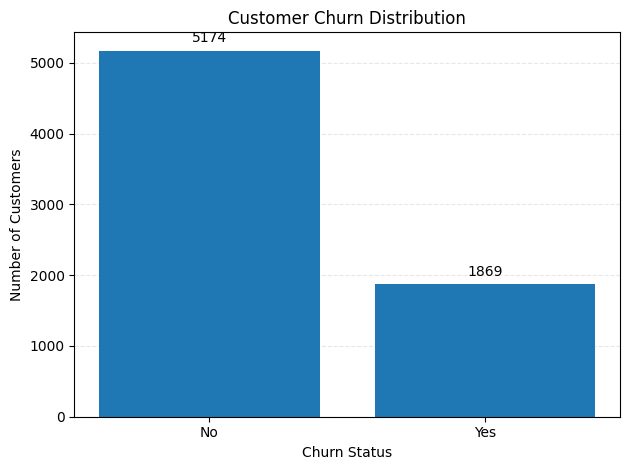

In [ ]:
import matplotlib.pyplot as plt

churn_counts = df_merged["churn_label"].value_counts().reindex(
    ["No", "Yes"]
)

bars = plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.bar_label(bars, fmt="%.0f", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

The dataset contains 7,043 customers, of whom 1,869 (26.54%) have churned, while 5,174 (73.46%) have remained.

This indicates that approximately one in four customers in the dataset has churned. The overall churn rate provides a baseline for further analysis to identify customer segments and service characteristics associated with churn.

## 4.2 Analyze churn by contract type

In [ ]:

contract_churn = df_merged.groupby("contract").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("churn_value", "sum"),
    churn_rate=("churn_value", "mean")
).reset_index()

contract_churn["churn_rate"] = (
    contract_churn["churn_rate"] * 100
).round(2)

print(contract_churn.sort_values("churn_rate", ascending=False))


         contract  total_customers  churned_customers  churn_rate
0  Month-to-Month             3610               1655       45.84
1        One Year             1550                166       10.71
2        Two Year             1883                 48        2.55


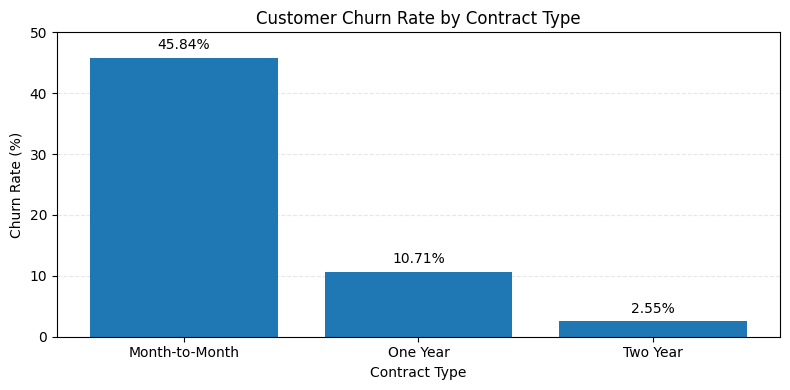

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

bars = plt.bar(
    contract_churn["contract"],
    contract_churn["churn_rate"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

Month-to-Month customers have the highest churn rate at 45.84%, compared with 10.71% for One Year customers and 2.55% for Two Year customers. The churn rate difference between Month-to-Month and Two Year customers is 43.29 percentage points.

This finding indicates a strong association between contract type and customer churn. Month-to-Month customers are a priority segment for further retention analysis.

## 4.3 Group tenure into meaningful customer lifecycle segments

In [ ]:

df_merged["tenure_group"] = pd.cut(
    df_merged["tenure"],
    bins=[-1, 6, 12, 24, 48, 60, 72],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

# Analyze churn by tenure group
tenure_churn = df_merged.groupby(
    "tenure_group", observed=True
).agg(
    total_customers=("customer_id", "count"),
    churned_customers=("churn_value", "sum"),
    churn_rate=("churn_value", "mean")
).reset_index()

tenure_churn["churn_rate"] = (
    tenure_churn["churn_rate"] * 100
).round(2)

print(tenure_churn)


   tenure_group  total_customers  churned_customers  churn_rate
0    0-6 months             1481                784       52.94
1   7-12 months              705                253       35.89
2  13-24 months             1024                294       28.71
3  25-48 months             1594                325       20.39
4  49-60 months              832                120       14.42
5  61-72 months             1407                 93        6.61


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, '0-6 months'),
  Text(1, 0, '7-12 months'),
  Text(2, 0, '13-24 months'),
  Text(3, 0, '25-48 months'),
  Text(4, 0, '49-60 months'),
  Text(5, 0, '61-72 months')])

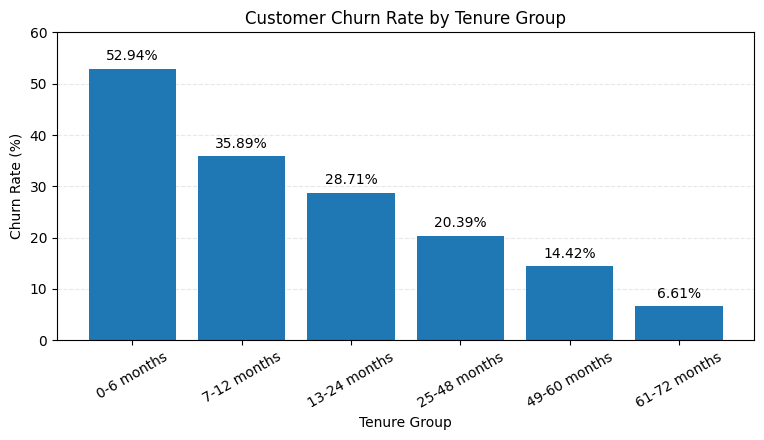

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

bars = plt.bar(
    tenure_churn["tenure_group"].astype(str),
    tenure_churn["churn_rate"]
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.xticks(rotation=30)

Customers with 0–6 months of tenure have the highest churn rate at 52.94%. The churn rate generally decreases as tenure increases, reaching 6.61% among customers with 61–72 months of tenure.

The difference between these two groups is 46.33 percentage points. This pattern indicates that newer customers are a key segment for retention analysis.

## 4.4 Group customers by monthly charges

In [ ]:

df_merged["monthly_charge_group"] = pd.qcut(
    df_merged["monthly_charges"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

# Analyze churn by monthly charge group
charge_churn = df_merged.groupby(
    "monthly_charge_group", observed=True
).agg(
    total_customers=("customer_id", "count"),
    churned_customers=("churn_value", "sum"),
    churn_rate=("churn_value", "mean")
).reset_index()

charge_churn["churn_rate"] = (
    charge_churn["churn_rate"] * 100
).round(2)

print(charge_churn)


  monthly_charge_group  total_customers  churned_customers  churn_rate
0                  Low             2351                373       15.87
1               Medium             2345                696       29.68
2                 High             2347                800       34.09


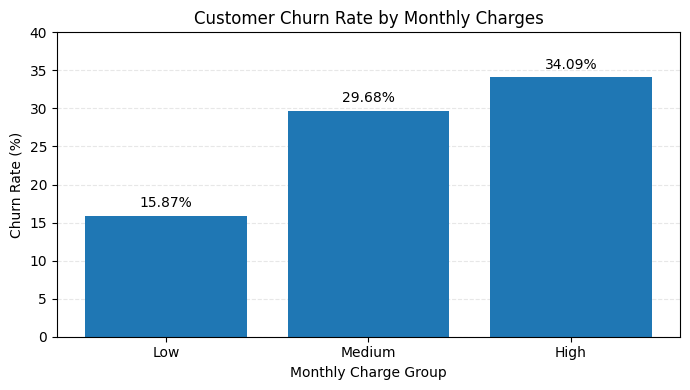

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

bars = plt.bar(
    charge_churn["monthly_charge_group"],
    charge_churn["churn_rate"]
)

plt.title("Customer Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

Customers in the High monthly charge group have the highest churn rate at 34.09%, followed by the Medium group at 29.68%. The Low group has the lowest churn rate at 15.87%.

The churn rate difference between the High and Low groups is 18.22 percentage points. This indicates an association between monthly charge levels and customer churn.

## 4.5 Analyze churn by contract type and tenure group

In [ ]:

contract_tenure_churn = df_merged.pivot_table(
    index="tenure_group",
    columns="contract",
    values="churn_value",
    aggfunc="mean",
    observed=True
) * 100

print(contract_tenure_churn.round(2))


contract      Month-to-Month  One Year  Two Year
tenure_group                                    
0-6 months             57.06      7.55      0.00
7-12 months            44.69      9.68      0.00
13-24 months           40.52      7.44      0.00
25-48 months           36.92     10.07      1.80
49-60 months           31.10     13.50      3.70
61-72 months           27.59     11.99      3.09


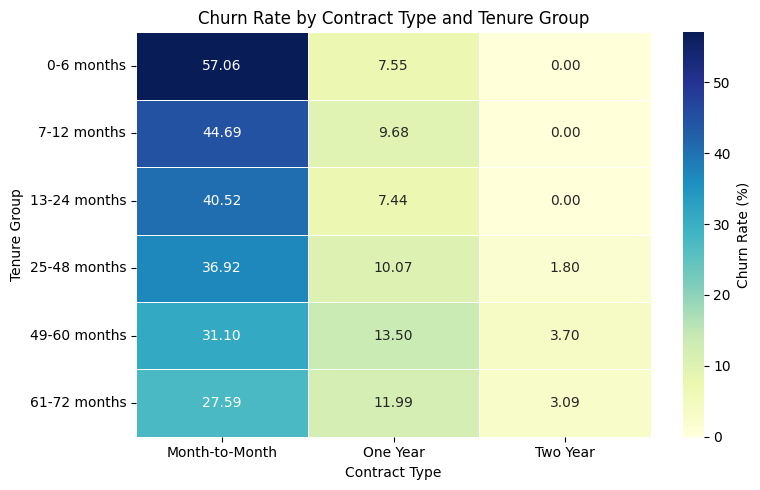

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.heatmap(
    contract_tenure_churn,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Churn Rate by Contract Type and Tenure Group")
plt.xlabel("Contract Type")
plt.ylabel("Tenure Group")
plt.tight_layout()
plt.show()

The heatmap shows that Month-to-Month customers have the highest churn rate across all tenure groups. The rate is highest among customers with 0–6 months of tenure at 57.06%, and remains at 27.59% among customers with 61–72 months of tenure.

One Year and Two Year contracts show substantially lower churn rates across the tenure groups. These findings suggest that Month-to-Month customers, particularly those in their first six months, are a priority segment for retention initiatives.

The results indicate an association between contract type, tenure, and churn, but do not establish causation. Rates for segments with smaller customer counts should also be interpreted cautiously.


## 4.6 Check customer counts for each contract and tenure group

In [ ]:

contract_tenure_counts = df_merged.pivot_table(
    index="tenure_group",
    columns="contract",
    values="customer_id",
    aggfunc="count",
    observed=True,
    fill_value=0
)

print(contract_tenure_counts)


contract      Month-to-Month  One Year  Two Year
tenure_group                                    
0-6 months              1367        53        61
7-12 months              546        93        66
13-24 months             686       215       123
25-48 months             715       546       333
49-60 months             209       326       297
61-72 months              87       317      1003


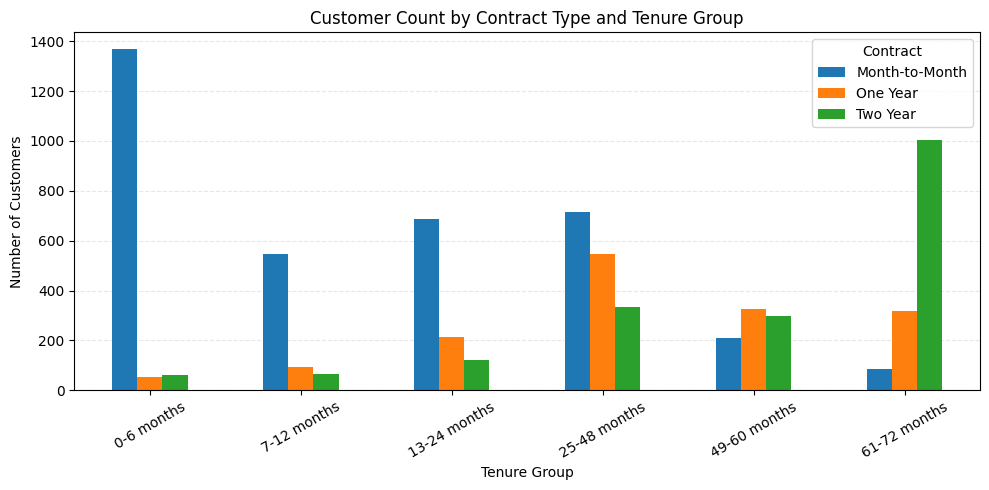

In [ ]:
import matplotlib.pyplot as plt

ax = contract_tenure_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Customer Count by Contract Type and Tenure Group")
ax.set_xlabel("Tenure Group")
ax.set_ylabel("Number of Customers")
ax.legend(title="Contract")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

The analysis shows that Month-to-Month customers have the highest churn rate across all tenure groups. Their churn rate decreases from 57.06% among customers with 0–6 months of tenure to 27.59% among customers with 61–72 months of tenure.

The customer distribution also differs substantially across contract types. Month-to-Month contracts dominate the shortest-tenure group, while Two Year contracts dominate the 61–72-month group. Therefore, churn rates should be interpreted alongside the number of customers in each segment, particularly for groups with relatively small populations.

Business implication: Customer retention efforts could prioritize Month-to-Month customers, especially those in their first six months. However, this analysis identifies associations rather than proving that contract type or tenure causes churn.

## 4.7 Churn rate by internet service type

In [ ]:
internet_churn = df_merged.groupby(
    "internet_service", dropna=False
).agg(
    total_customers=("customer_id", "count"),
    churned_customers=("churn_value", "sum"),
    churn_rate=("churn_value", "mean")
).reset_index()

internet_churn["churn_rate"] = (
    internet_churn["churn_rate"] * 100
).round(2)

internet_churn

,internet_service,total_customers,churned_customers,churn_rate
0,No,1526,113,7.40
1,Yes,5517,1756,31.83


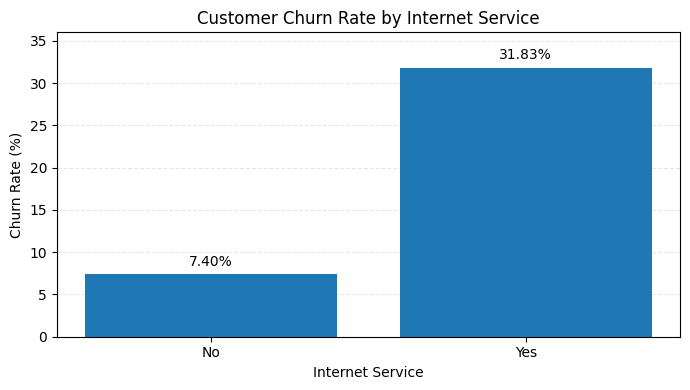

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

bars = plt.bar(
    internet_churn["internet_service"].astype(str),
    internet_churn["churn_rate"]
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 36)
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

Customers with internet service have a churn rate of 31.83%, compared with 7.40% among customers without internet service. This represents a difference of 24.43 percentage points.

Business implication: Customers with internet service may be an important segment for retention initiatives. Further investigation into internet service types, pricing, and service quality could help identify factors associated with their higher churn rate.

This finding shows an association and does not establish that having internet service causes customer churn.

In [ ]:
df_merged.to_csv(
    "telco_churn_analysis.csv",
    index=False
)

In [ ]:
from google.colab import files

files.download("telco_churn_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>